### MIE370 Project 2 --- Classification and Ensemble models
**Deadline: Oct 25, 21:00 [The deadline is firm and will be enforced strictly. Plan ahead and submit hours before the deadline to avoid the risk of lateness penalty.]**

**Academic Integrity**

This project is individual - it is to be completed on your own. If you have questions, please post your query in the MIE370 Piazza Q&A forums (the answer might be useful to others!).

Do not share your code with others, or post your work online. Do not submit code that you have not written yourself. Students suspected of plagiarism on projects or assessments will be referred to the department for formal discipline for breaches of the Student Code of Conduct.

Please fill out the following:

Full Name: Angeline Wong  

Student ID: 1010918027

UTorID: wonga128

**Three submission files are required:**

For submitting this project, three files must be submitted on Quercus by the project deadline:

1) The complete Jupyter file (in .ipynb format) (that completely compiles on Google colab without any errors regardless of the computer used.)

2) A self-contained and complete HTML printout of the same Jupyter file with all the output printed as well as all the code, text cells, comments, and figures.

3) Appendix pdf file of all prompts and all responses for all interactions you have had regarding this project with any AI assistant tool (Chat GPT etc.). If you do not use any AI assistant tool at all, this appendix pdf file is not needed.

**Policy regarding the use of AI assistant tools**

If you use a generative AI tool (e.g., ChatGPT, GitHub Copilot, or any other similar tool) to get ideas and/or partial answers for projects or assignments or to generate any code and/or text, you must declare in your submission the tools that you have used and describe the usage, and include in your submission an appendix that captures all the interactions (prompts and responses).

You will not be penalized for the declared use of such AI assistant tools, and the grading decisions will be based on your original contributions as well as the efforts that you make to check and/or correct the answers provided by the tool. Students are ultimately accountable for the work they submit. Failure to fully declare the use of this tool will be considered "unauthorized assistance" and will have consequences (See B.I. of the [U of T CODE OF BEHAVIOUR ON ACADEMIC MATTERS](https://governingcouncil.utoronto.ca/secretariat/policies/code-behaviour-academic-matters-july-1-2019))

## **Marking Scheme:**

This project is worth **9 percent** of your final grade.

Draw a plot or table where necessary to summarize your findings.

**Practice Vectorized coding**: If you need to write a loop in your solution, think about how you can implement the same functionality with vectorized operations. Try to avoid loops as much as possible (in some cases, loops are inevitable).




### How to obtain an **HTML** file from an **IPYNB** file

1. Download the IPYNB file of your complete project: `File -> Download .ipynb`

2. Click on the Files icon on the far left menu of a new Colab session

3. Select & upload your `.ipynb` file you just downloaded, and then copy its path (right click) (you might need to hit the Refresh button before your file shows up)


4. Replace XXXX with the copied path and then execute the following in a Colab cell:
```
%%shell
jupyter nbconvert --to html XXXX
```

5. An HTML version of your notebook will appear in the Colab session files and you can download it.

6. Submit **both** <font color='red'>`HTML` and `IPYNB`</font>  files on Quercus (before the deadline) for grading.



More info on converting IPYNB to HTML: https://stackoverflow.com/a/64487858



## Working in VS Code

Install the required packages if needed:

```bash
python3 -m pip install numpy pandas scipy matplotlib seaborn scikit-learn ipykernel nbconvert
```

Open the notebook, select the correct Python kernel, and run the setup cell before starting the assignment.

# Assignment Roadmap

| Part | Main topic | Marks |
|---|---|---:|
| Part 0 | Getting started: identify the target and the number of features | 2 |
| Part A | Pre-processing: encoding, X/y preparation, downsampling, train/test split, standardization | 13 |
| Part B | KNN: sweeping `k` with cross-validation, overfitting vs. underfitting | 20 |
| Part C | Tree-based models (DT, RF, gradient boosting) and hyperplane-based models (logistic regression, polynomial and RBF SVMs) with hyperparameter tuning, plus a CV summary table | 35 |
| Part D | Feature importance: permutation importance for every tuned model, comparing models, re-training on the important features | 20 |
| Part E | Test-set evaluation: performance metrics, confusion table, ROC and AUC | 10 |
| **Total** | | **100** |
| Bonus | Tune and evaluate up to 2 extra models (SGT, EBM, XGBoost, FIGS) | +10 |

Required total: **100 marks**. The optional question is worth up to **10 additional bonus marks**.


### Setup

Run the next code cell before Part 0. It imports the required libraries. 

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, expon

from sklearn.model_selection import train_test_split, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

# Project 2 **[100 Marks]**
You are going to apply several ML methods for a predictive task on a new dataset.

We're going to work with the [MAGIC Gamma Telescope dataset](https://www.openml.org/d/43971). When a high-energy particle hits the atmosphere, it creates a shower of secondary particles that emits a faint flash of light. A ground-based telescope camera records this flash as an image, which is summarized by fitting an ellipse to it. The task is to classify each shower as either a **gamma ray** (`g`, the signal astronomers are interested in) or a **hadron** (`h`, background cosmic rays), using the shape of that ellipse.


In [38]:
from sklearn.datasets import fetch_openml

df = fetch_openml(data_id=43971, as_frame=True).frame
df.columns = df.columns.str.rstrip(':')  # OpenML column names end with ':'

## Part 0: Getting started **[2 Marks]**

* Identify the target column (the variable we aim to predict)? **class** **[1]**
* How many features do we have in this dataset in order to predict the target? **10** **[1]**

In [39]:
df.head()
# Identify the target column
target_column = [col for col in df.columns if not col.startswith('f')][0]
print(f"Target Column: {target_column}")

# Identify how many features 
num_features = len(df.columns) - 1
print(f"Number of Features: {num_features}")

Target Column: class
Number of Features: 10


# Part A: Pre-processing **[13 Marks Total]**

## Part A1: Encoding the Target **[2 Marks]**

Each row in this dataset represents a single particle shower recorded by the telescope.

The columns describe the shape of the ellipse fitted to the shower image, such as its length, width, brightness, and orientation. The `class` column indicates whether the shower was caused by a gamma ray or a hadron.

Convert the `class` column so that it contains 1 (if the shower is a gamma ray, `g`) or 0 (if it is a hadron, `h`). This will be the target value to classify the data. **[2]**

In [40]:
### YOUR CODE HERE ###
df['class'] = df['class'].astype(str).map({'g': 1, 'h': 0})
print(df['class'].value_counts())
df.head()

class
1    6688
0    6688
Name: count, dtype: int64


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,69.2979,26.8809,3.1930,0.2065,0.1074,39.6296,44.3457,-23.0604,9.3234,248.750,1
1,24.5939,10.1418,2.5676,0.5007,0.2693,-8.4503,15.2452,-7.0283,17.0056,173.288,1
2,55.4800,27.1606,3.1826,0.2299,0.1225,43.1016,54.2556,13.7406,32.2220,262.181,1
3,12.6594,11.7413,2.1351,0.7033,0.3846,-15.8596,9.4522,-8.7126,43.5434,227.711,1
4,38.6204,20.5632,2.9770,0.2478,0.1270,-13.8229,-31.3983,-13.1337,5.8671,192.467,1


## Part A2: Preparing X and y **[2 Marks]**

The first argument of [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) is the **X value** (the quantities we use in order to predict), and the second argument is the **y value** (the quantity we want to predict).

Prepare the variables `X` (all columns except `class`) and `y` (the `class` column). **[2]**

Check [this](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html) example to see how to drop columns.

*hint: use axis = 1 to drop columns, otherwise it's defaulted to axis = 0 which is used to drop rows*

In [41]:
### YOUR CODE HERE ###
X = df.drop('class', axis=1)
y = df['class']

print(f"X Shape: {X.shape}")
print(f"y Shape: {y.shape}")


X Shape: (13376, 10)
y Shape: (13376,)


## Part A3: Downsampling **[3 Marks]**

Several models in Part C are tuned with hundreds of cross-validated fits, which would take a long time on all 13,376 showers. Downsample `X` and `y` to 3,000 samples via **stratified sampling with `random_state=24`**. Make sure the rows of `X` and `y` still line up after downsampling. **[2]**

Print the shape of `X` and the number of samples in each class after downsampling. **[1]**

*HINT: [consider how sklearn's `train_test_split` function might be able to help do this](https://www.geeksforgeeks.org/machine-learning/how-to-implement-stratified-sampling-with-scikit-learn/)*

In [42]:
### YOUR CODE HERE ###
# Downsample X and y by stratifying y in train_test_split 
X, _, y, _ = train_test_split(X, y, train_size=3000, stratify=y, random_state=24)

# Print the shape of X and the number of samples in each class (0 and 1)
print(f"X Shape after downsampling: {X.shape}") # Should be 3000
print("\nSamples in each class after downsampling:") # Should be 1500 each
print(y.value_counts())

X Shape after downsampling: (3000, 10)

Samples in each class after downsampling:
class
1    1500
0    1500
Name: count, dtype: int64


## Part A4: Data Splitting **[2 Marks]**

**Split the downsampled dataset** into a train and a test set **"80:20"**, **stratified based on `class`** (`stratify=y`), and use **``random_state=24``**. The test set is set aside (untouched) for final evaluation, once hyperparameter optimization is complete. **[2]**

In [43]:
### YOUR CODE HERE ###
# Split the dataset into train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=24
)
X_train_raw = X_train.copy()

# Print shapes (verify if 80:20 split happened)
print(f"X_train split: {X_train.shape}")
print(f"X_test split:  {X_test.shape}")
print(f"y_train split: {y_train.shape}")
print(f"y_test split:  {y_test.shape}")


X_train split: (2400, 10)
X_test split:  (600, 10)
y_train split: (2400,)
y_test split:  (600,)


## Part A5: Standardization **[4 Marks]**

Standardize the training and test data ([Help](https://scikit-learn.org/stable/modules/preprocessing.html)). **[2]**

Use `seaborn.lmplot` ([help here](https://seaborn.pydata.org/generated/seaborn.lmplot.html)) to draw a plot of the training set where the x-axis is `fAlpha`, the y-axis is `fLength`, and the color of each datapoint indicates its class. Then draw the same plot using the standardized features. What's different? **Why do they look similar?** Based on your observation, what is the advantage of standardization? **[2]**

**Note:** When we standardize a dataset, it matters if the data points are in our training set or test set. The training set is available for us to train a model - we can use it however we want. The test set, however, represents a subset of data that is not available for us during training. For example, the test set can represent the data that someone who bought our model would use to see how the model performs (which they are not willing to share with us).
Therefore, we cannot use the mean or standard deviation of the whole dataset to standardize it - we can only use the mean and standard deviation of the training set. When the model is ready for testing, we provide our scalers (mean and standard deviation of our training set) to the person who is going to test the model. They can scale their data (test set) with our training set's mean and standard deviation. It is unlikely that the scaled test set would exactly have a mean of zero and a standard deviation of one, but there is no such requirement for the model to perform well.

**To summarize: We fit the StandardScaler only on the training set. We transform both training and test sets with that scaler.**

**Use the standardized data for all remaining parts of this project.**

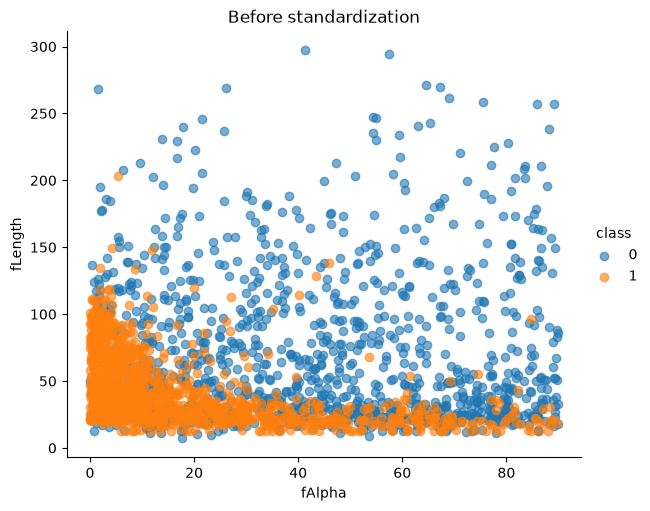

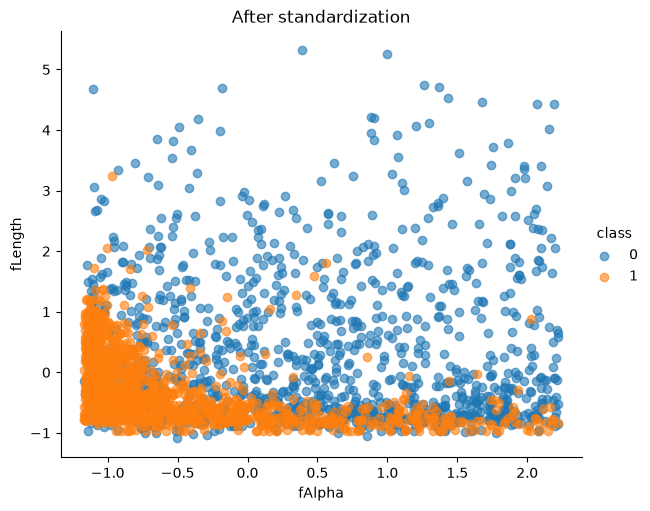

In [44]:
### YOUR CODE HERE ###
# 1. Prepare data for Before Standardization
df_og = X_train_raw.copy()
df_og['class'] = y_train # y_train is the target variable

# 2. Prepare data for After Standardization
scaler = StandardScaler() # Standardize
X_train_scaled = scaler.fit_transform(X_train) # Fit only on training data + transform
X_test_scaled = scaler.transform(X_test) # Transform only

# Convert back to df (features are now scaled, same column and index)
X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

# Make a copy of the scaled data
df_scaled = X_train.copy()
df_scaled['class'] = y_train # y_train is the target variable

# Plot 1: Before Standardization (Left)
sns.lmplot(data=df_og, x='fAlpha', y='fLength', hue='class',
           fit_reg=False, height=5, aspect=1.2, scatter_kws={'alpha': 0.6})
plt.title('Before standardization')
plt.show()

# Plot 2: After Standardization (Right)
sns.lmplot(data=df_scaled, x='fAlpha', y='fLength', hue='class',
           fit_reg=False, height=5, aspect=1.2, scatter_kws={'alpha': 0.6})
plt.title('After standardization')
plt.show()

In [45]:
# Part A5: Analysis of Graphs above
""" 
1. What's different?
The scales of the horizontal and vertical axes have changed significantly. In the raw plot (left), the axes show the original physical units (`fAlpha` spans 
from 0 to 90, and `fLength` spans from 0 to 300). In the standardized plot (right), the axes are centered at zero and represent standard deviations.

2. Why do they look similar?
Standardization is a linear transformation. All it does is shift the center of the data and rescales its variance, but it does not change the relative positions, 
distances, or patterns between individual data points. Therefore, the geometric distribution shape remains perfectly preserved.

3. What is the advantage of standardization?
The advantage of standardization is its ability to scale all 10 feature measurements onto a completely uniform numerical scale. This ensures that machine learning 
algorithms calculating spatial distances or geometric boundaries treat every feature with equal weight, rather than allowing a feature with naturally massive raw 
values (like `fLength`) to completely dominate the model's calculations and training process. 
"""

" \n1. What's different?\nThe scales of the horizontal and vertical axes have changed significantly. In the raw plot (left), the axes show the original physical units (`fAlpha` spans \nfrom 0 to 90, and `fLength` spans from 0 to 300). In the standardized plot (right), the axes are centered at zero and represent standard deviations.\n\n2. Why do they look similar?\nStandardization is a linear transformation. All it does is shift the center of the data and rescales its variance, but it does not change the relative positions, \ndistances, or patterns between individual data points. Therefore, the geometric distribution shape remains perfectly preserved.\n\n3. What is the advantage of standardization?\nThe advantage of standardization is its ability to scale all 10 feature measurements onto a completely uniform numerical scale. This ensures that machine learning \nalgorithms calculating spatial distances or geometric boundaries treat every feature with equal weight, rather than allowing a 

# Part B: KNN **[20 Marks Total]**

## Part B1: Sweeping `k` **[8 Marks]**

Let's create a KNN Model to predict whether a shower was caused by a gamma ray from the shape of its image!

Using 5-fold cross-validation on the standardized training set, sweep `k` (number of neighbors) from 1 to 90. For each `k`, record both the **mean training accuracy** and the **mean validation accuracy** across the folds. Show both curves on a single plot of accuracy vs `k`. **[8]**

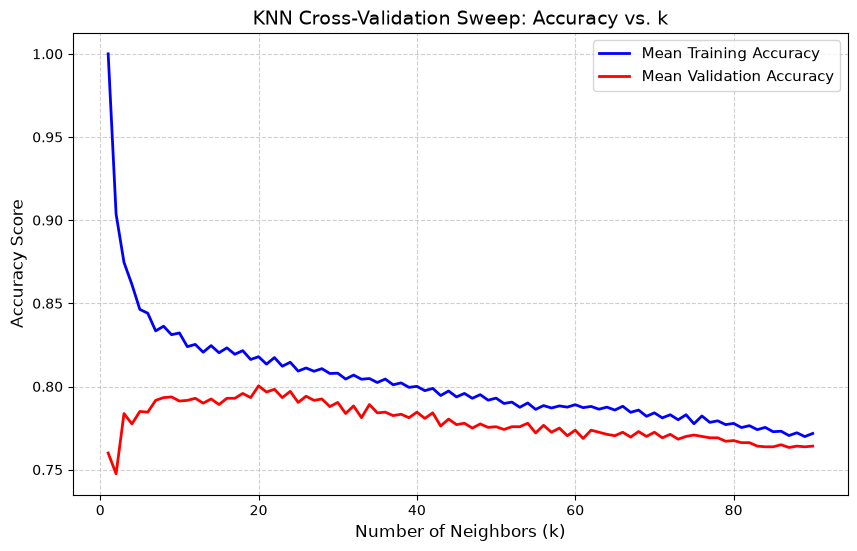

In [46]:
### YOUR CODE HERE ###
# 1. Define range of k values (1 to 90)
k_values = range(1,91)

# 2. Record each mean score (training accuracy and validation accuracy)
mean_train_accuracies = []
mean_val_accuracies = []

# 3. Loop through each k value + calculate 5-fold cross validation
for k in k_values:
    # Initialize knn classifier
    knn = KNeighborsClassifier(n_neighbors=k)

    # Calculate train and validaiton scores using cross validation
    # cross_validate(model, features, targets, cross folds, if returning a score, parallel processing)
    scores = cross_validate(knn, X_train, y_train, cv=5, return_train_score=True, n_jobs=-1)

    # Store the averages across the 5 folds
    mean_train_accuracies.append(np.mean(scores['train_score']))
    mean_val_accuracies.append(np.mean(scores['test_score']))

# 4. Plot both curves onto a single plot
plt.figure(figsize=(10, 6))
plt.plot(k_values, mean_train_accuracies, label='Mean Training Accuracy', color='blue', linewidth=2)
plt.plot(k_values, mean_val_accuracies, label='Mean Validation Accuracy', color='red', linewidth=2)

plt.title('KNN Cross-Validation Sweep: Accuracy vs. k', fontsize=14)
plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

## Part B2: Best `k` **[4 Marks]**

What is the best `k`? What is the highest mean cross-validation accuracy? **[2]**

Pick the best `k` and refit a KNN model with it on the full standardized training set. This refit model is the KNN model you will use in Parts C3, D and E. **[2]**

In [47]:
### YOUR CODE HERE ###
# 1. Find the best k (aka. the highest mean validation accuracy)
best_index = np.argmax(mean_val_accuracies) # get the max value's index
best_k = k_values[best_index] # gets the k_value
highest_accuracy = mean_val_accuracies[best_index]

# Print the best k value and highest mean cross-validation accuracy
print(f"Best k value: {best_k}")
print(f"Highest mean cross-validation accuracy {highest_accuracy}")

# 2. Refit the final KNN model on the full standardization training set
best_knn = KNeighborsClassifier(n_neighbors=best_k) # for best k
best_knn.fit(X_train, y_train) # refit to training dataset

Best k value: 20
Highest mean cross-validation accuracy 0.8004166666666667


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",20
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [48]:
# Part B2: Answering questions from above
""" 
1. What is the best k? The best k is 20
2. What is the highest mean cross-validation accuracy? The highest mean cross-validation accuracy is 0.8004.
"""

' \n1. What is the best k? The best k is 20\n2. What is the highest mean cross-validation accuracy? The highest mean cross-validation accuracy is 0.8004.\n'

## Part B3: Overfitting vs. Underfitting **[8 Marks]**

Using the training and validation curves from Part B1:

* Which range of `k` leads to overfitted models, and which range leads to underfitted models? Justify your answer using the gap between the two curves. **[4]**
* Why is the training accuracy exactly 1.0 at `k = 1`? Explain in terms of how KNN makes predictions, and why this does not mean `k = 1` is a good model. **[4]**

*Your answer here*
1. What are the ranges of k for overfitting and underfitting the model?

Based off the graph from above and the best k (k=20):
- Overfitted Range (1 <= k < ~8):
    At k=1 the training accuracy is 1.0 (100%) while the validation accuracy is only about 75%. As k increases towards 8, the gap between the validation 
    and training curves closes quickly. The wide difference in accuracy implies that the model is memorizing random noise from the training dataset rather 
    than learning general features.
- Best Range (~8 <= k <= ~30):
    Validation accuracy is highest here and peaks at k=20 (about 80%). The gap between the two curves is small, so the model fits well.
- Underfitted Range (k > ~40):
    From k=40 to k=90 both the training and validation accuracy keep decreasing together, and at k=90 they are well below the peak. This decline in accuracy 
    implies that the model is becoming too simple and is averaging over a large neighbourhood, which smooths out the local patterns and features that the model 
    was trying to extract. This causes the predictions on both the training and validation datasets to be poor. The gap is small here because both scores are 
    low, not because the model is good.

2. Why is the training accuracy exactly 1.0 at k=1?

Training accuracy is exactly 1.0 at k=1 since the KNN model only evaluates the closest data point to itself (which is itself) in the training set. Since the closest 
data point at k=1 is itself, the distance is exactly 0 which makes the model have a 100% training accuracy score.
This is not good for the model as it has only seen itself as a reference point, making it hard to generalize to new, unseen data. Only having k=1 would make the decision 
boundary extremely sensitive to random noise and outliers in the training set. The lack of generalization shown (in k=1) is supported by how low the validation accuracy 
is at k=1 (about 75%, among the lowest in the sweep) compared to the peak of about 80%.

# Part C: Other Built-in Models & Hyperparameter Tuning **[35 Marks Total]**

In this part, you will use some built-in models, and **tune their hyperparameters** to achieve high accuracy/scores. Use the standardized training set with all features.

The models you will be using are:

1. Decision Tree (Part C1.1)
2. Random Forest (Part C1.2)
3. Gradient Boosted Trees (Part C1.3)
4. Logistic Regression (Part C2.1)
5. SVM with Polynomial Kernel (Part C2.2)
6. SVM with RBF Kernel (Part C2.3)

(5 marks per model)

For every model that has a `random_state` parameter, set `random_state=24` (e.g. `DecisionTreeClassifier(random_state=24)`) so your results are reproducible.

Keep the best tuned version of each model (e.g. `best_estimator_` from the search), since you will need them in Parts D and E.

## Part C-1: Tree-based Models **[15 Marks Total]**

## Part C1.1: Decision Tree Classifier **[5 Marks]**

Train a decision tree classifier on the standardized dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) and check the example there.) Tune the hyperparameters `max_depth` and `min_samples_split` using [RandomizedSearchCV ](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with n_iter=250, you should set the ranges of the hyperparameters as the following:

* `'max_depth': randint(1, 10)`
* `'min_samples_split': randint(2, 50)`


For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best performance using decision tree is 0.987654321 with a max depth of 8 and a min samples split of 25*


In [49]:
### YOUR CODE HERE ###
# 1. Define parmeter distributions for RandomSearchCV
dt_param_dist = {
    'max_depth': randint(1, 10),
    'min_samples_split': randint(2, 50)
}

# 2. Get estimator from the baseline decision tree model
dt_classifier = DecisionTreeClassifier(random_state=24)

# 3.Set up RandomizedSearchCV with the parameters
dt_search = RandomizedSearchCV(
    estimator=dt_classifier,
    param_distributions=dt_param_dist,
    n_iter=250,
    cv=5,
    verbose=2,
    random_state=24,
    n_jobs=-1,
    return_train_score=True
)

# 4. Fit the search on the training dataset 
# Fiting is not only neaded to normalize, but to use: .best_score_, best_params_ and .best_estimator_
dt_search.fit(X_train, y_train) 

# 5. Record the best results
best_score = dt_search.best_score_ # Highest mean cross-validation score
best_params = dt_search.best_params_ # Dictionary of optimal hyperparameters found
best_dt_model = dt_search.best_estimator_ # Best trained model instance 

# 6. Print results
print(f"Best performance using decision tree is {best_score:.9f} with a max depth of {best_params['max_depth']} and a min samples split of {best_params['min_samples_split']}")

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best performance using decision tree is 0.797500000 with a max depth of 5 and a min samples split of 49


## Part C1.2: Random Forests **[5 Marks]**

Train a Random Forest classifier on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and check the example there.) Tune the `n_estimators` and `max_features` parameters of the classifier using [RandomizedSearchCV ](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with n_iter=250, using the following hyperparameter ranges:

* `max_features : ['sqrt', 'log2', 0.1, 0.25, 0.5]`,
* `n_estimators : randint(10, 200)`


For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best n_estimators: 60, Best Max Features: log2, Best Accuracy: 0.987654321*


In [50]:
### YOUR CODE HERE ###
# 1. Define parmeter distributions for RandomSearchCV
rf_param_dist = {
    'max_features': ['sqrt', 'log2', 0.1, 0.25, 0.5],
    'n_estimators': randint(10, 200)
}

# 2. Get estimator from the baseline random forest model
rf_classifier = RandomForestClassifier(random_state=24)

# 3. Set up RandomizedSearchCV with the parameters
rf_search = RandomizedSearchCV(
    estimator=rf_classifier,
    param_distributions=rf_param_dist,
    n_iter=250,
    cv=5,
    verbose=2,
    random_state=24,
    n_jobs=-1,
    return_train_score=True
)

# 4. Fit the search on the training dataset
rf_search.fit(X_train, y_train)

# 5. Record the best results
best_rf_score = rf_search.best_score_ # Highest mean cross-validation score
best_rf_params = rf_search.best_params_ # Dictionary of optimal hyperparameters found
best_rf_model = rf_search.best_estimator_ # Best trained model instance for later parts

# 6. Print results
print(f"Best n_estimators: {best_rf_params['n_estimators']}, Best Max Features: {best_rf_params['max_features']}, Best Accuracy: {best_rf_score:.9f}")

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best n_estimators: 101, Best Max Features: 0.1, Best Accuracy: 0.837500000


## Part C1.3: Gradient Boosting Classifier **[5 Marks]**

Similarly, train a Gradient Boosting classifier on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) and check the example there.)


Then tune the hyperparameters `n_estimators`, `learning_rate`, and `max_depth` using [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

For the ranges of those hyperparameters please do the following:  

*   `learning_rate = [0.007, 0.053, 0.082, 0.099, 0.130]`
*   `max_depth = [1,2,3] `
*   `n_estimators = [1, 10, 50, 100, 300, 500]`


For GridSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *n_estimators: 100, Best Learning Rate: 0.053, Best Max Depth: 2, Best Accuracy: 0.987654321*

In [51]:
### YOUR CODE HERE ###
# 1. Define the parameter grid
gb_param_grid = {
    'learning_rate': [0.007, 0.053, 0.082, 0.099, 0.130],
    'max_depth': [1,2,3],
    'n_estimators': [1, 10, 50, 100, 300, 500]
}

# 2. Get estimator from the baseline gradient boosting model
gb_classifier = GradientBoostingClassifier(random_state=24)

# 3. Set up GridSearchCV with the parameters
gb_search = GridSearchCV(
    estimator=gb_classifier,
    param_grid=gb_param_grid,
    cv=5,
    verbose=2,
    n_jobs=-1,
    return_train_score=True
)

# 4. Fit the search on the training dataset
gb_search.fit(X_train, y_train)

# 5. Record the best results
best_gb_score = gb_search.best_score_ # Highest mean cross-validation score
best_gb_params = gb_search.best_params_ # Dictionary of optimal hyperparameters found
best_gb_model = gb_search.best_estimator_ # Best trained model instance

# 6. Print results
print(f"n_estimators: {best_gb_params['n_estimators']}, Best Learning Rate: {best_gb_params['learning_rate']}, Best Max Depth: {best_gb_params['max_depth']}, Best Accuracy: {best_gb_score:.9f}")

Fitting 5 folds for each of 90 candidates, totalling 450 fits
n_estimators: 300, Best Learning Rate: 0.082, Best Max Depth: 2, Best Accuracy: 0.836250000


## Part C-2: Hyperplane-based Models **[15 Marks Total]**

## Part C2.1: Logistic Regression **[5 Marks]**

Train a logistic regression classifier on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) and check the example there.) Set `max_iter=1000` so the solver has enough iterations to converge.

Then tune the regularization parameter `C` using [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html). Smaller values of `C` mean stronger regularization.

set:

* `'C': np.logspace(-3, 3, 13)`

For GridSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best C: 0.1, Best Accuracy: 0.987654321*

In [52]:
### YOUR CODE HERE ###
# 1. Define the parameter grid using the exact logspace expression
lr_param_grid = {
    'C': np.logspace(-3, 3, 13)
}

# 2. Get estimator from the baseline logistic regression model
lr_classifier = LogisticRegression(max_iter=1000, random_state=24)

# 3. Set up GridSearchCV with the parameters
lr_search = GridSearchCV(
    estimator=lr_classifier,
    param_grid=lr_param_grid,
    cv=5,
    verbose=2,
    n_jobs=-1,
    return_train_score=True
)

# 4. Fit the search on the training dataset
lr_search.fit(X_train, y_train)

# 5. Record the best results
best_lr_score = lr_search.best_score_ # Highest mean cross-validation score
best_lr_params = lr_search.best_params_ # Dictionary of optimal hyperparameters found
best_lr_model = lr_search.best_estimator_ # Best trained model instance

# 6. Print results
print(f"Best C: {best_lr_params['C']}, Best Accuracy: {best_lr_score:.9f}")

Fitting 5 folds for each of 13 candidates, totalling 65 fits
Best C: 0.01, Best Accuracy: 0.767083333


## Part C2.2: SVM with Polynomial Kernel  **[5 Marks]**

Train an SVM with Polynomial Kernel on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) and check the example there.) with `poly` as the kernel setting. Tune the `C` and `degree` parameters of the classifier using [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with `n_iter = 250`.

set:
* ` 'C': expon(scale=10)`
* `'degree': randint(2, 6)`
    
For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best C: 2, Best degree: 5, Best Accuracy: 0.98754321*

In [53]:
### YOUR CODE HERE ###
# 1. Define the parameter distributions using exact scipy tools
svm_param_dist = {
    'C': expon(scale=10),
    'degree': randint(2, 6)
}

# 2. Get estimator from the baseline SVM model with poly kernel setting
svm_classifier = SVC(kernel='poly', random_state=24)

# 3. Set up RandomizedSearchCV with the parameters
svm_search = RandomizedSearchCV(
    estimator=svm_classifier,
    param_distributions=svm_param_dist,
    n_iter=250,
    cv=5,
    verbose=2,
    random_state=24,
    n_jobs=-1,
    return_train_score=True
)

# 4. Fit the search on the training dataset
svm_search.fit(X_train, y_train)

# 5. Record the best results
best_svm_score = svm_search.best_score_ # Highest mean cross-validation score
best_svm_params = svm_search.best_params_ # Dictionary of optimal hyperparameters found
best_svm_model = svm_search.best_estimator_ # Best trained model instance

# 6. Print results
print(f"Best C: {best_svm_params['C']}, Best degree: {best_svm_params['degree']}, Best Accuracy: {best_svm_score:.9f}")

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best C: 37.66727001197502, Best degree: 3, Best Accuracy: 0.809166667


## Part C2.3: SVM with Radial Kernel **[5 Marks]**

Similarly train an SVM with radial kernel on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) and check the example there.) with `rbf` as the kernel value. Tune the `C` and `gamma` parameters of the classifier using [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with `n_iter = 250`.

set:

*  `'C': expon(scale=10)`
* `'gamma': [0.01, 0.1, 1, 10]`

For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best C: 2, Best Gamma: 0.1, Best Accuracy: 0.98754321*

In [54]:
### YOUR CODE HERE ###
# 1. Define the parameter distributions
svm_rbf_param_dist = {
    'C': expon(scale=10),
    'gamma': [0.01, 0.1, 1, 10]
}

# 2. Get estimator from the baseline SVM model with rbf kernel setting
svm_rbf_classifier = SVC(kernel='rbf', random_state=24)

# 3. Set up RandomizedSearchCV with the parameters
svm_rbf_search = RandomizedSearchCV(
    estimator=svm_rbf_classifier,
    param_distributions=svm_rbf_param_dist,
    n_iter=250,
    cv=5,
    verbose=2,
    random_state=24,
    n_jobs=-1,
    return_train_score=True
)

# 4. Fit the search on the training dataset 
svm_rbf_search.fit(X_train, y_train)

# 5. Record the best results
best_svm_rbf_score = svm_rbf_search.best_score_ # Highest mean cross-validation score
best_svm_rbf_params = svm_rbf_search.best_params_ # Dictionary of optimal hyperparameters found
best_svm_rbf_model = svm_rbf_search.best_estimator_ # Best trained model instance

# 6. Print results
print(f"Best C: {best_svm_rbf_params['C']}, Best Gamma: {best_svm_rbf_params['gamma']}, Best Accuracy: {best_svm_rbf_score:.9f}")

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best C: 12.168248098503692, Best Gamma: 0.1, Best Accuracy: 0.834583333


## Part C3: Cross-Validation Summary **[5 Marks]**

So far you have developed 7 models: the tuned KNN from Part B and the 6 models above.

Make a table of the best mean cross-validation accuracy and the best hyperparameters for all 7 models.

In [55]:
### YOUR CODE HERE ###
# 1. Pull metrics from your saved model variables (From all 7 models)
summary_data = [
    {
        "Model": "K-Nearest Neighbors (KNN)", 
        "Best Hyperparameters": f"k = {best_k}", 
        "Best Mean CV Accuracy": highest_accuracy
    },
    {
        "Model": "Decision Tree", 
        "Best Hyperparameters": f"max_depth = {dt_search.best_params_['max_depth']}, min_samples_split = {dt_search.best_params_['min_samples_split']}", 
        "Best Mean CV Accuracy": dt_search.best_score_
    },
    {
        "Model": "Random Forest", 
        "Best Hyperparameters": f"n_estimators = {rf_search.best_params_['n_estimators']}, max_features = {rf_search.best_params_['max_features']}", 
        "Best Mean CV Accuracy": rf_search.best_score_
    },
    {
        "Model": "Gradient Boosting", 
        "Best Hyperparameters": f"n_estimators = {gb_search.best_params_['n_estimators']}, learning_rate = {gb_search.best_params_['learning_rate']}, max_depth = {gb_search.best_params_['max_depth']}", 
        "Best Mean CV Accuracy": gb_search.best_score_
    },
    {
        "Model": "Logistic Regression", 
        "Best Hyperparameters": f"C = {lr_search.best_params_['C']}", 
        "Best Mean CV Accuracy": lr_search.best_score_
    },
    {
        "Model": "SVM (Polynomial Kernel)", 
        "Best Hyperparameters": f"C = {svm_search.best_params_['C']:.5f}, degree = {svm_search.best_params_['degree']}", 
        "Best Mean CV Accuracy": svm_search.best_score_
    },
    {
        "Model": "SVM (Radial/RBF Kernel)", 
        "Best Hyperparameters": f"C = {svm_rbf_search.best_params_['C']:.5f}, gamma = {svm_rbf_search.best_params_['gamma']}", 
        "Best Mean CV Accuracy": svm_rbf_search.best_score_
    }
]

# 2. Convert to a pandas df
df_summary = pd.DataFrame(summary_data)

# 3. Format the accuracy column to display 9 decimal places
df_summary['Best Mean CV Accuracy'] = df_summary['Best Mean CV Accuracy'].map('{:.9f}'.format)

# 4. Display the table
df_summary

,Model,Best Hyperparameters,Best Mean CV Accuracy
0,K-Nearest Neighbors (KNN),k = 20,0.800416667
1,Decision Tree,"max_depth = 5, min_samples_split = 49",0.797500000
2,Random Forest,"n_estimators = 101, max_features = 0.1",0.837500000
3,Gradient Boosting,"n_estimators = 300, learning_rate = 0.082, max...",0.836250000
4,Logistic Regression,C = 0.01,0.767083333
5,SVM (Polynomial Kernel),"C = 37.66727, degree = 3",0.809166667
6,SVM (Radial/RBF Kernel),"C = 12.16825, gamma = 0.1",0.834583333


# Part D: Feature Importance **[20 Marks Total]**

Different models can rely on very different features to make their predictions. In this part, you will measure how much each tuned model depends on each feature using [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

**How permutation importance works.** Start with a fitted model and a dataset, and record the model's accuracy on that data (the *baseline*). Then, for one feature at a time:

1. Randomly shuffle the values in that feature's column, leaving every other column (and the labels) unchanged.
2. Re-compute the model's accuracy on the shuffled data. The model is **not** re-trained.
3. The importance of the feature is the drop in accuracy: `baseline accuracy - shuffled accuracy`.

Shuffling keeps the feature's overall distribution the same but breaks its relationship with the target, so the model can no longer use it. If accuracy drops a lot, the model relies heavily on that feature. If accuracy barely changes (importance near 0), the model is not using it. Because shuffling is random, the process is repeated several times (`n_repeats`) and the drops are averaged.

A few things to keep in mind:

* It works for **any** model, since it only needs the model's predictions. This lets us compare KNN, trees, and SVMs on the same scale.
* It measures what a **specific fitted model** relies on, not how useful a feature is in general. Two models can give very different importances on the same data.
* When two features are strongly correlated (e.g. `fConc` and `fConc1`), shuffling one of them may hurt little, since the model can still get the same information from the other. Both can then look less important than they really are.

## Part D1: Permutation Importance **[8 Marks]**

For each of the 7 best models from Part C3, compute the permutation importance of every feature using [`permutation_importance`](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) on the standardized **training** set, with `n_repeats=10` and `random_state=24`. Store the mean importances of all models in a single DataFrame (rows = features, columns = models). **[8]**

*Do not use the test set here - it stays untouched until Part E.*

In [56]:
### YOUR CODE HERE ###
# 1. Since I saved the best model for each, relocated them into a dictonary by using the model as the key name
models_dict = {
    "KNN": best_knn,
    "Decision Tree": best_dt_model,
    "Random Forest": best_rf_model,
    "Gradient Boosting": best_gb_model,
    "Logistic Regression": best_lr_model,
    "SVM (Polynomial)": best_svm_model,
    "SVM (Radial)": best_svm_rbf_model
}

# 2. Dictionary for importance results
importance_results = {}

# 3. Calculate permutation importance on X_train and y_train for each model
for model_name, model_instance in models_dict.items():
    # Compute permutation importance using parameters requested above
    result = permutation_importance(
        estimator=model_instance,
        X=X_train,
        y=y_train,
        n_repeats=10,
        random_state=24,
        n_jobs=-1
    )
    
    # Save mean scores into the dictionary I made in part 2
    importance_results[model_name] = result.importances_mean

# 4. Convert the dictionary into a df
df_importance = pd.DataFrame(importance_results, index=X_train.columns) # using X_train.columns to match feature names

# 5. Display 
df_importance

,KNN,Decision Tree,Random Forest,Gradient Boosting,Logistic Regression,SVM (Polynomial),SVM (Radial)
fLength,0.032417,0.107583,0.056458,0.081792,0.064375,0.139708,0.115083
fWidth,0.023292,0.039250,0.070542,0.086083,0.009375,0.087125,0.063292
fSize,0.058292,0.067667,0.087667,0.102542,0.013125,0.138792,0.116750
fConc,0.022875,0.078667,0.021000,0.050875,0.005292,0.105625,0.152000
fConc1,0.024667,0.018750,0.015208,0.036833,0.015792,0.059458,0.047250
fAsym,0.013208,0.014958,0.012750,0.008500,-0.000167,0.020667,0.020958
fM3Long,0.024375,0.023583,0.030792,0.016708,0.004458,0.050875,0.030333
fM3Trans,0.014125,0.000000,0.013542,0.005083,0.000167,0.039708,0.023083
fAlpha,0.180083,0.207792,0.217833,0.219125,0.194208,0.198750,0.207542
fDist,0.025708,0.000000,0.031167,0.026208,0.000875,0.042417,0.050375


## Part D2: Visualization **[3 Marks]**

Visualize the importances of all features for all 7 models in a single figure (e.g. a heatmap or a grouped bar chart). **[3]**

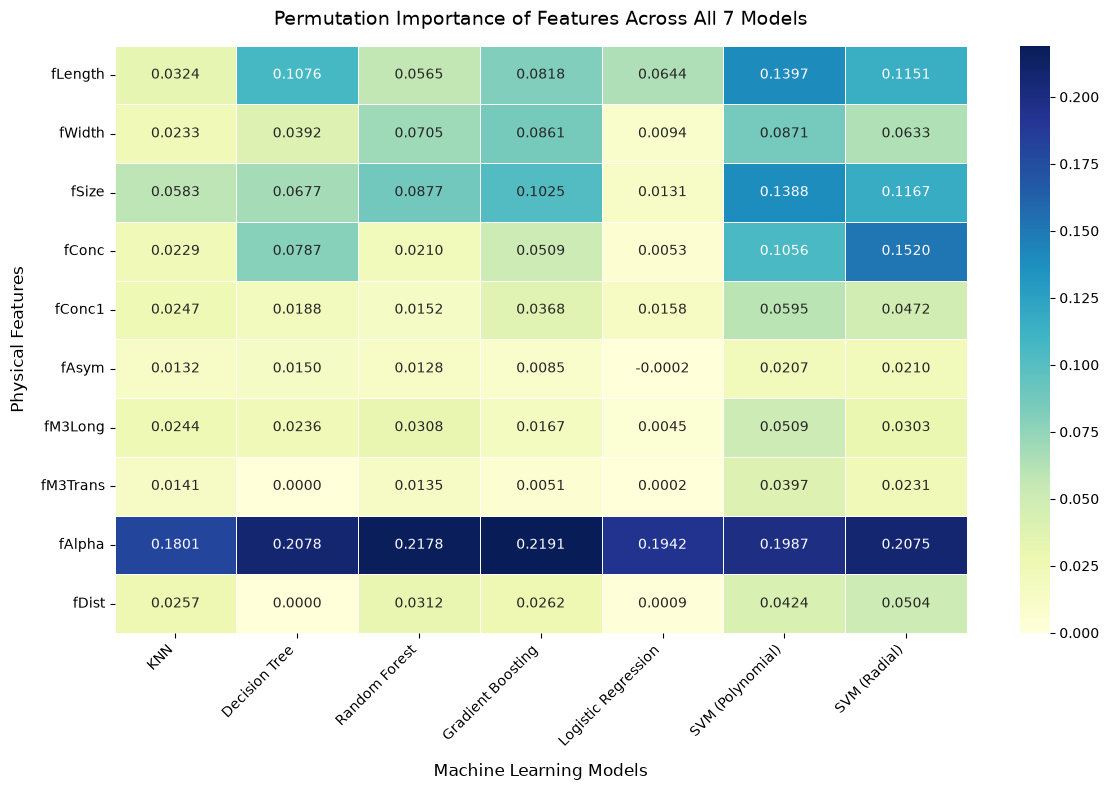

In [57]:
### YOUR CODE HERE ###
# 1. Set up figure size
plt.figure(figsize=(12, 8))

# 2. Create a heatmap using the importance df
# annot=True -> shows the numerical values inside each square
# cmap='YlGnBu' -> displays a nice colour palette
sns.heatmap(df_importance, annot=True, fmt=".4f", cmap="YlGnBu", linewidths=0.5)

# 3. itles + Labels
plt.title("Permutation Importance of Features Across All 7 Models", fontsize=14, pad=15)
plt.xlabel("Machine Learning Models", fontsize=12, labelpad=10)
plt.ylabel("Physical Features", fontsize=12, labelpad=10)

# 4. Rotate Labels (by 45% so nothing overlaps)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# 5. Display
plt.tight_layout()
plt.show()

## Part D3: Comparing Models **[4 Marks]**

* Which features are among the top 3 for most models? Which features does almost no model rely on? **[2]**
* Which models disagree the most about which features matter? Give a reason for the disagreement based on how those models make predictions. **[2]**

*Your answer here*
1. What are the top 3 features among the models? 

fAlpha is the most important feature for every single model (about 0.18 to 0.22). fSize and fLength are the next most common, but the ranking 
after fAlpha varies as fSize is in the top 3 for KNN, Random Forest, Gradient Boosting, and both SVMs, and fLength is in the top 3 for KNN, 
Decision Tree, Logistic Regression, and the Polynomial SVM. A few models rank other features highly instead (fWidth for Random Forest and 
Gradient Boosting, fConc for the Decision Tree and RBF SVM). Overall, the top 3 features across most models are fAlpha, fSize, and fLength.

2. Which features do almost no models rely on?

The features that almost no models rely on are fM3Trans and fAsym. Their permutation importance scores are extremely close to zero for most 
models (KNN, Decision Tree, Random Forest, Gradient Boosting, and Logistic Regression), with some models even showing a value of 0.0000 or a 
slightly negative score. The SVMs give them slightly more weight (about 0.02 to 0.04), but they are still among the lowest-ranked features. 
This suggests that shuffling these columns has little to no impact on the accuracy of the predictions.

3. Which models disagree the most about which features matter?
Logistic Regression and SVM (Radial/RBF Kernel) show the greatest disagreement about the features.
- Logistic Regression concentrates nearly all of its predictive importance on just two features (fAlpha at about 0.19 and fLength at about 0.06), 
  while assigning very little importance (under 0.02) to the rest.
- SVM Radial spreads its importance across many different features, giving high scores to fAlpha, fConc, fSize, and fLength (all above 0.11).

4. Give a reason for the disagreement based on how those models make predictions?
This disagreement happens because of how the two models construct their decision boundaries.
- Logistic Regression is a linear model that can only use a feature through a straight-line (weighted sum) relationship with the target. Features 
  whose effect depends on other features, or is non-linear, contribute very little to its predictions.
- SVM (Radial Kernel) works by mapping the data into a non-linear space using local similarity. This allows the SVM to find complex, interlocking 
  shape patterns among multiple features at once, which a simple linear boundary completely misses.
Overall, Logistic Regression is too focused on 2 features, while SVM (Radial) relies on almost all of the features. Correlated features such as 
fConc and fConc1 can also split or hide importance between them, which adds to the differences between models.

## Part D4: Re-training on the Important Features **[5 Marks]**

Pick one of your 7 models and select its most important features based on your results from Part D1. Explain how you decided which features to keep (e.g. a threshold on the importance, or the top few features). **[1]**

Re-tune the model on the standardized training set using **only the selected features**, with the same hyperparameter search and cross-validation settings you used originally. Report the best mean cross-validation accuracy. **[2]**

How did performance change compared to the same model trained on all 10 features? Why do you think it changed (or didn't)? **[2]**

*Do not use the test set here either.*

In [58]:
### YOUR CODE HERE ###
# Top 3 features according to the Decision Tree's own permutation importance (Part D1)
important_features = df_importance['Decision Tree'].nlargest(3).index.tolist()
print("Selected features:", important_features)   # expected: fAlpha, fLength, fConc
X_train_top3 = X_train[important_features]

# 2. Parameter distribution (Picked Decision Tree cause its the fastest)
dt_param_dist_top3 = {
    'max_depth': randint(1, 10),
    'min_samples_split': randint(2, 50)
}

# 3. Re-instantiate the baseline Decision Tree model
dt_classifier_top3 = DecisionTreeClassifier(random_state=24)

# 4. Set up the RandomizedSearchCV parameteres
dt_search_top3 = RandomizedSearchCV(
    estimator=dt_classifier_top3,
    param_distributions=dt_param_dist_top3,
    n_iter=250,
    cv=5,
    verbose=2,
    random_state=24,
    n_jobs=-1,
    return_train_score=True
)

# 5. Fit the search on the top 3 training dataset
dt_search_top3.fit(X_train_top3, y_train)

# 6. Print the new best performance
best_score_top3 = dt_search_top3.best_score_
print(f"New Decision Tree Cross-Validation Accuracy: {best_score_top3:.9f}")

Selected features: ['fAlpha', 'fLength', 'fConc']
Fitting 5 folds for each of 250 candidates, totalling 1250 fits
New Decision Tree Cross-Validation Accuracy: 0.773333333


*Your answer here*
*Your answer here*
1. How I decided which features to keep?

I chose the Decision Tree and kept its top 3 features based on its own column in the Part D1 permutation importance results: fAlpha (0.208), fLength (0.108), and fConc (0.079). I used a rank-based selection strategy, since there is a clear drop after these three (the next feature, fSize, is 0.068), and the tree gives fM3Trans and fDist an importance of exactly 0.

2. Best mean cross-validation accuracy

The new best mean cross-validation accuracy using only the top 3 features is 0.773333333.

3. Performance comparison and why it changed

The original model was trained on all 10 features and achieved an accuracy of 0.7975, which is slightly higher than the 0.7733 of the new model trained on only 3 features. This small drop in accuracy (about 2.4 percentage points) most likely happened because, while the top 3 features capture most of the information the tree relies on, the model loses the smaller, secondary information from the other 7 features (for example fSize, fWidth, and fM3Long, which each still had some importance in D1). However, since the accuracy did not drop by a lot, this suggests that the top 3 features account for most of what the Decision Tree uses.

# Part E: Evaluation on Test Data **[10 Marks Total]**


## Part E1: Performance measures **[6 Marks]**

Select the model with the highest mean cross-validation accuracy in your Part C3 table (do **not** use the test set to choose), and apply it to the test dataset initially set aside.

Treat gamma rays (`class` = 1) as the positive class. The fall-out rate is the false positive rate: FP / (FP + TN).

Compute the following using the standardized test data (note: never standardize the y data, only standardize the x data):



1.   Accuracy,
2.   Precision,
3.   Recall,
4.   Fall-out rate,
5.   F1 score,
6.   Confusion table

(1 mark for each performance metric)

In [59]:
### YOUR CODE HERE ###
# 1. Generate predictions on the standardized test set
y_pred = best_rf_model.predict(X_test) # The best model in Part C3 was Random Forest

# 2. Compute standard metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# 3. Compute Confusion Table for Fall-out rate
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fall_out_rate = fp / (fp + tn)
conf_matrix = confusion_matrix(y_test, y_pred)

# 4. Print out all 6 required metrics clearly for grading
print(f"1. Accuracy:       {accuracy:.9f}")
print(f"2. Precision:      {precision:.9f}")
print(f"3. Recall:         {recall:.9f}")
print(f"4. Fall-out rate:  {fall_out_rate:.9f}")
print(f"5. F1 score:       {f1:.9f}")
print("6. Confusion table:")
cm_df = pd.DataFrame(conf_matrix,
                     index=['Actual 0 (hadron)', 'Actual 1 (gamma)'],
                     columns=['Predicted 0 (hadron)', 'Predicted 1 (gamma)'])
print("6. Confusion table:")
print(cm_df)


1. Accuracy:       0.850000000
2. Precision:      0.826086957
3. Recall:         0.886666667
4. Fall-out rate:  0.186666667
5. F1 score:       0.855305466
6. Confusion table:
6. Confusion table:
                   Predicted 0 (hadron)  Predicted 1 (gamma)
Actual 0 (hadron)                   244                   56
Actual 1 (gamma)                     34                  266


## Part E2: ROC and AUC **[4 Marks]**

Using the same selected model from the previous part, plot the ROC curve **[2]** and report its AUC **[2]** on the test data.

The ROC curve needs a continuous score for each test sample, not a 0/1 prediction. Use `predict_proba(X_test)[:, 1]` if your model has it; otherwise use `decision_function(X_test)`. For example, `SVC` only has `predict_proba` when created with `probability=True`, but it always has `decision_function`.


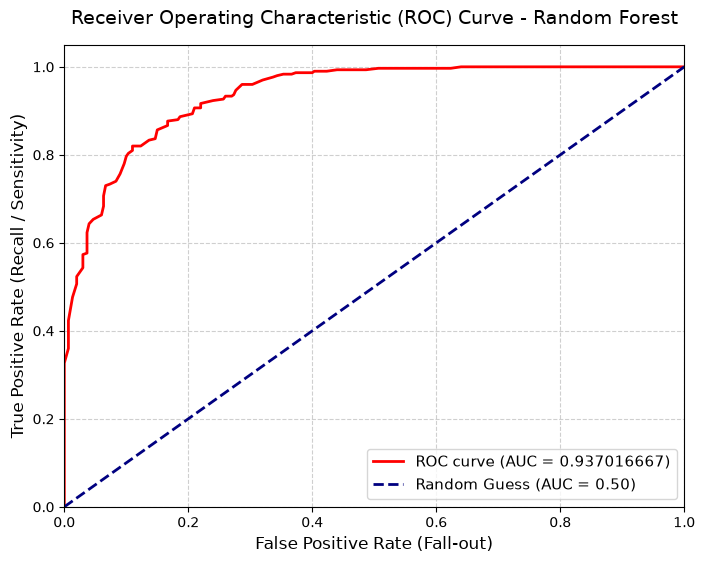

Final Test Set AUC Score: 0.937016667


In [60]:
### YOUR CODE HERE ###
# 1. Need continuous scores (copy code from above)
y_scores = best_rf_model.predict_proba(X_test)[:, 1]

# 2. Calculate the FPR and TPR points for the curve
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# 3. Calculate the AUC score
auc_score = roc_auc_score(y_test, y_scores)

# 4. Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='red', lw=2, label=f'ROC curve (AUC = {auc_score:.9f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')

# 5. Graph configurations
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Fall-out)', fontsize=12)
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve - Random Forest', fontsize=14, pad=15)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower right", fontsize=11)
plt.show()

# 6. Report the final AUC score
print(f"Final Test Set AUC Score: {auc_score:.9f}")

# Bonus: Additional Models **[up to 10 Bonus Marks]**

Pick **up to 2** of the models below. For each model you choose **[5 marks each]**:

1. Tune at least 2 hyperparameters using 5-fold cross-validation on the standardized training set (use `random_state=24` wherever applicable), and report the best mean cross-validation accuracy and hyperparameters. **[2]**
2. Evaluate the best model on the test set using the same metrics as Part E1 and E2 (accuracy, precision, recall, fall-out rate, F1 score, confusion table, and AUC). **[2]**
3. Compare its test performance to your best model from Part E in one or two sentences. **[1]**

| Model | Package | Suggested hyperparameters |
|---|---|---|
| [Shape Generalized Tree (SGT)](https://sgtlearn.readthedocs.io/en/latest/index.html) | `pip install sgtlearn`, then `from sgtlearn import SGTClassifier` | `max_depth`, `min_samples_leaf`, `inner_max_leaf_nodes` |
| [Explainable Boosting Machine (EBM)](https://interpret.ml/docs/ebm.html) | `pip install interpret`, then `from interpret.glassbox import ExplainableBoostingClassifier` | `learning_rate`, `max_leaves`, `interactions` |
| [XGBoost](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html) | `pip install xgboost`, then `from xgboost import XGBClassifier` | `n_estimators`, `max_depth`, `learning_rate` |
| [Fast Interpretable Greedy-Tree Sums (FIGS)](https://csinva.io/imodels/figs.html) | `pip install imodels`, then `from imodels import FIGSClassifier` | `max_rules`, `max_trees`, `min_impurity_decrease` |

*Note: EBMs are slower to fit than the other models (a few seconds per fit), so keep its search small (around 10 candidate settings).*

In [61]:
### YOUR CODE HERE ###